## question (h)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from openpyxl import load_workbook

paths = [root / name for root in (Path.cwd(), Path.cwd() / "upload")
         for name in ("Problem_Set9_2026(1).xlsx", "Problem_Set9_2026.xlsx")]
FILE = next((p for p in paths if p.is_file()), None)
if FILE is None:
    raise FileNotFoundError("Place the uploaded Problem_Set9_2026(1).xlsx beside this notebook.")

wb = load_workbook(FILE, read_only=True, data_only=True)
display(pd.DataFrame([(s.title, s.max_row, s.max_column) for s in wb],
                     columns=["Worksheet", "Rows", "Columns"]))

markets = {
    "US": "U.S. equities", "UK": "U.K. equities", "EU": "Europe equities",
    "JP": "Japan equities", "EQ": "Equity indices", "FX": "Currencies",
    "FI": "Fixed income", "CM": "Commodities"
}
cols = [f"{factor}^{market}" for market in markets for factor in ("VAL", "MOM")]
ws = wb["Value and momentum factors"]
assert [c.value for c in next(ws.iter_rows(min_row=5, max_row=5))] == ["DATE"] + cols

evidence = {}
for row in ws.iter_rows(min_row=6, min_col=2, max_col=17):
    for name, cell in zip(cols, row):
        if isinstance(cell.value, (int, float)):
            assert "%" in cell.number_format, f"Unexpected units: {name}"
            evidence.setdefault(name, cell.value)
wb.close()

display(pd.DataFrame({
    "Stored value": {k: f"{v:.6f}" for k, v in evidence.items()},
    "Return (%)": {k: f"{100*v:.4f}" for k, v in evidence.items()}
}))
print("Monthly decimal returns: 0.01 = 1%. Long-short factors: no RF subtraction.")

,Worksheet,Rows,Columns
0,Value and momentum factors,658,17
1,TSMOM,500,45
2,Fama-French factors,1201,8
3,"Carry, BAB, and Quality",1203,6
4,AMP factors,657,4
5,HF indices,440,22


,Stored value,Return (%)
MOM^UK,0.011241,1.1241
VAL^CM,0.010065,1.0065
MOM^CM,-0.029481,-2.9481
VAL^US,-0.059689,-5.9689
MOM^US,0.043027,4.3027
MOM^EU,0.049547,4.9547
MOM^JP,-0.031214,-3.1214
VAL^EQ,0.012178,1.2178
MOM^EQ,-0.012178,-1.2178
VAL^FX,0.034577,3.4577


Monthly decimal returns: 0.01 = 1%. Long-short factors: no RF subtraction.


In [ ]:
raw = pd.read_excel(
    FILE, sheet_name="Value and momentum factors", header=4,
    na_values=["NA", "N/A", -999, -99.99, -9999]
)
assert raw.columns.tolist() == ["DATE"] + cols

dates = pd.to_datetime(raw.pop("DATE"), errors="raise").dt.to_period("M")
assert dates.notna().all() and not dates.duplicated().any()

raw.index = pd.PeriodIndex(dates, name="Month")
raw = (raw.apply(pd.to_numeric, errors="raise")
       .replace([np.inf, -np.inf], np.nan).sort_index())

audit = pd.DataFrame({
    "Market": [markets[c.split("^")[1]] for c in cols],
    "First month": [str(raw[c].first_valid_index()) for c in cols],
    "Last month": [str(raw[c].last_valid_index()) for c in cols],
    "Missing months": raw.isna().sum()
}, index=cols)
display(audit)

R = raw.dropna(how="any").copy()
T, N = R.shape
assert T > N and N == 16 and np.isfinite(R.to_numpy()).all()
assert R.index.equals(
    pd.period_range(R.index[0], R.index[-1], freq="M", name="Month")
)
print(f"Common sample: {R.index[0]}–{R.index[-1]} | {T} months | {N} factors")
print(f"Excluded {len(raw) - T} months.")

,Market,First month,Last month,Missing months
VAL^US,U.S. equities,1972-02,2026-05,1
MOM^US,U.S. equities,1972-02,2026-05,1
VAL^UK,U.K. equities,1981-07,2026-05,114
MOM^UK,U.K. equities,1972-01,2026-05,0
VAL^EU,Europe equities,1981-07,2026-05,114
MOM^EU,Europe equities,1974-02,2026-05,25
VAL^JP,Japan equities,1981-07,2026-05,114
MOM^JP,Japan equities,1974-02,2026-05,25
VAL^EQ,Equity indices,1977-03,2025-01,78
MOM^EQ,Equity indices,1977-03,2025-01,78


Common sample: 1983-01–2025-01 | 505 months | 16 factors
Excluded 148 months; no imputation or forward filling.


In [3]:
ANN = 12
mu, Sigma = R.mean(), R.cov(ddof=1)
m, S, one = mu.to_numpy(), Sigma.to_numpy(), np.ones(N)

assert np.linalg.eigvalsh(S).min() > 0
z, v = np.linalg.solve(S, m), np.linalg.solve(S, one)
A, B, C = one @ v, one @ z, m @ z
D = A*C - B**2
assert B > 0 and D > 0

w_tan, w_gmv = z / B, v / A
tangency_returns = R @ w_tan

weights = pd.DataFrame({
    "Market": [markets[c.split("^")[1]] for c in cols],
    "Type": ["Value" if c.startswith("VAL") else "Momentum" for c in cols],
    "Tangency weight": w_tan
}, index=pd.Index(cols, name="Workbook column"))
display(weights.assign(**{
    "Tangency weight": weights["Tangency weight"].map("{:.3%}".format)
}))

combos = pd.DataFrame({
    f"50/50 {k}": (R[f"VAL^{k}"] + R[f"MOM^{k}"]) / 2 for k in markets
})
portfolio_returns = pd.concat(
    [R, combos, tangency_returns.rename("Tangency")], axis=1
)

summary = pd.DataFrame({
    "Monthly mean": portfolio_returns.mean(),
    "Monthly volatility": portfolio_returns.std(ddof=1),
    "Annual mean": ANN * portfolio_returns.mean(),
    "Annual volatility": np.sqrt(ANN) * portfolio_returns.std(ddof=1)
})
summary["Annual Sharpe"] = summary["Annual mean"] / summary["Annual volatility"]
display(summary.apply(
    lambda s: s.map("{:.3f}".format if s.name == "Annual Sharpe"
                    else "{:.3%}".format)
))

print(f"Net weight: {w_tan.sum():.6f}")
print(f"Sum of absolute factor weights: {abs(w_tan).sum():.6f}")
print(f"Negative weights: {(w_tan < 0).sum()}")
print(f"Covariance condition number: {np.linalg.cond(S):.2f}")
print("Arithmetic annualization: mean × 12; volatility × √12; Sharpe × √12.")
print("Factor weights sum to one; underlying long-short leg exposures are not shown.")

,Market,Type,Tangency weight
Workbook column,,,
VAL^US,U.S. equities,Value,-3.138%
MOM^US,U.S. equities,Momentum,-0.362%
VAL^UK,U.K. equities,Value,6.374%
MOM^UK,U.K. equities,Momentum,8.610%
VAL^EU,Europe equities,Value,3.909%
MOM^EU,Europe equities,Momentum,5.178%
VAL^JP,Japan equities,Value,12.378%
MOM^JP,Japan equities,Momentum,4.972%
VAL^EQ,Equity indices,Value,11.859%


,Monthly mean,Monthly volatility,Annual mean,Annual volatility,Annual Sharpe
VAL^US,0.128%,4.375%,1.535%,15.155%,0.101
MOM^US,0.442%,4.590%,5.303%,15.899%,0.334
VAL^UK,0.280%,4.116%,3.360%,14.259%,0.236
MOM^UK,0.655%,4.493%,7.860%,15.564%,0.505
VAL^EU,0.191%,3.119%,2.294%,10.805%,0.212
MOM^EU,0.580%,3.770%,6.961%,13.060%,0.533
VAL^JP,0.640%,4.007%,7.682%,13.879%,0.553
MOM^JP,0.151%,4.554%,1.817%,15.775%,0.115
VAL^EQ,0.201%,2.639%,2.418%,9.142%,0.264
MOM^EQ,0.399%,3.052%,4.789%,10.573%,0.453


Net weight: 1.000000
Sum of absolute factor weights: 1.070015
Negative weights: 2
Covariance condition number: 65.07
Arithmetic annualization: mean × 12; volatility × √12; Sharpe × √12.
Factor weights sum to one; underlying long-short leg exposures are not shown.


In [4]:
gmv_mean = B / A
targets = np.linspace(
    gmv_mean, 1.25 * summary["Annual mean"].max() / ANN, 600
)
W_frontier = (
    (C - B*targets)[:, None] * v
    + (A*targets - B)[:, None] * z
) / D

frontier_vol = np.sqrt(
    ANN * np.einsum("ij,jk,ik->i", W_frontier, S, W_frontier)
)
frontier_mean = ANN * targets

assert np.isclose(w_tan.sum(), 1)
assert np.isclose(tangency_returns.mean(), w_tan @ m)
assert np.isclose(tangency_returns.var(ddof=1), w_tan @ S @ w_tan)
assert np.isclose(summary.loc["Tangency", "Annual Sharpe"], np.sqrt(ANN*C))
assert np.allclose(W_frontier.sum(axis=1), 1)
assert np.allclose(W_frontier @ m, targets)
assert np.allclose(
    frontier_vol**2 / ANN, (A*targets**2 - 2*B*targets + C) / D
)
assert np.isclose(w_gmv @ S @ w_gmv, 1/A)
assert (
    summary.loc["Tangency", "Annual Sharpe"]
    >= summary["Annual Sharpe"].max() - 1e-10
)

min_variance = (
    A*portfolio_returns.mean()**2 - 2*B*portfolio_returns.mean() + C
) / D
assert (portfolio_returns.var(ddof=1) >= min_variance - 1e-12).all()

print("Validation passed: weights, sample moments, frontier constraints, and maximum Sharpe.")

Validation passed: weights, sample moments, frontier constraints, and maximum Sharpe.


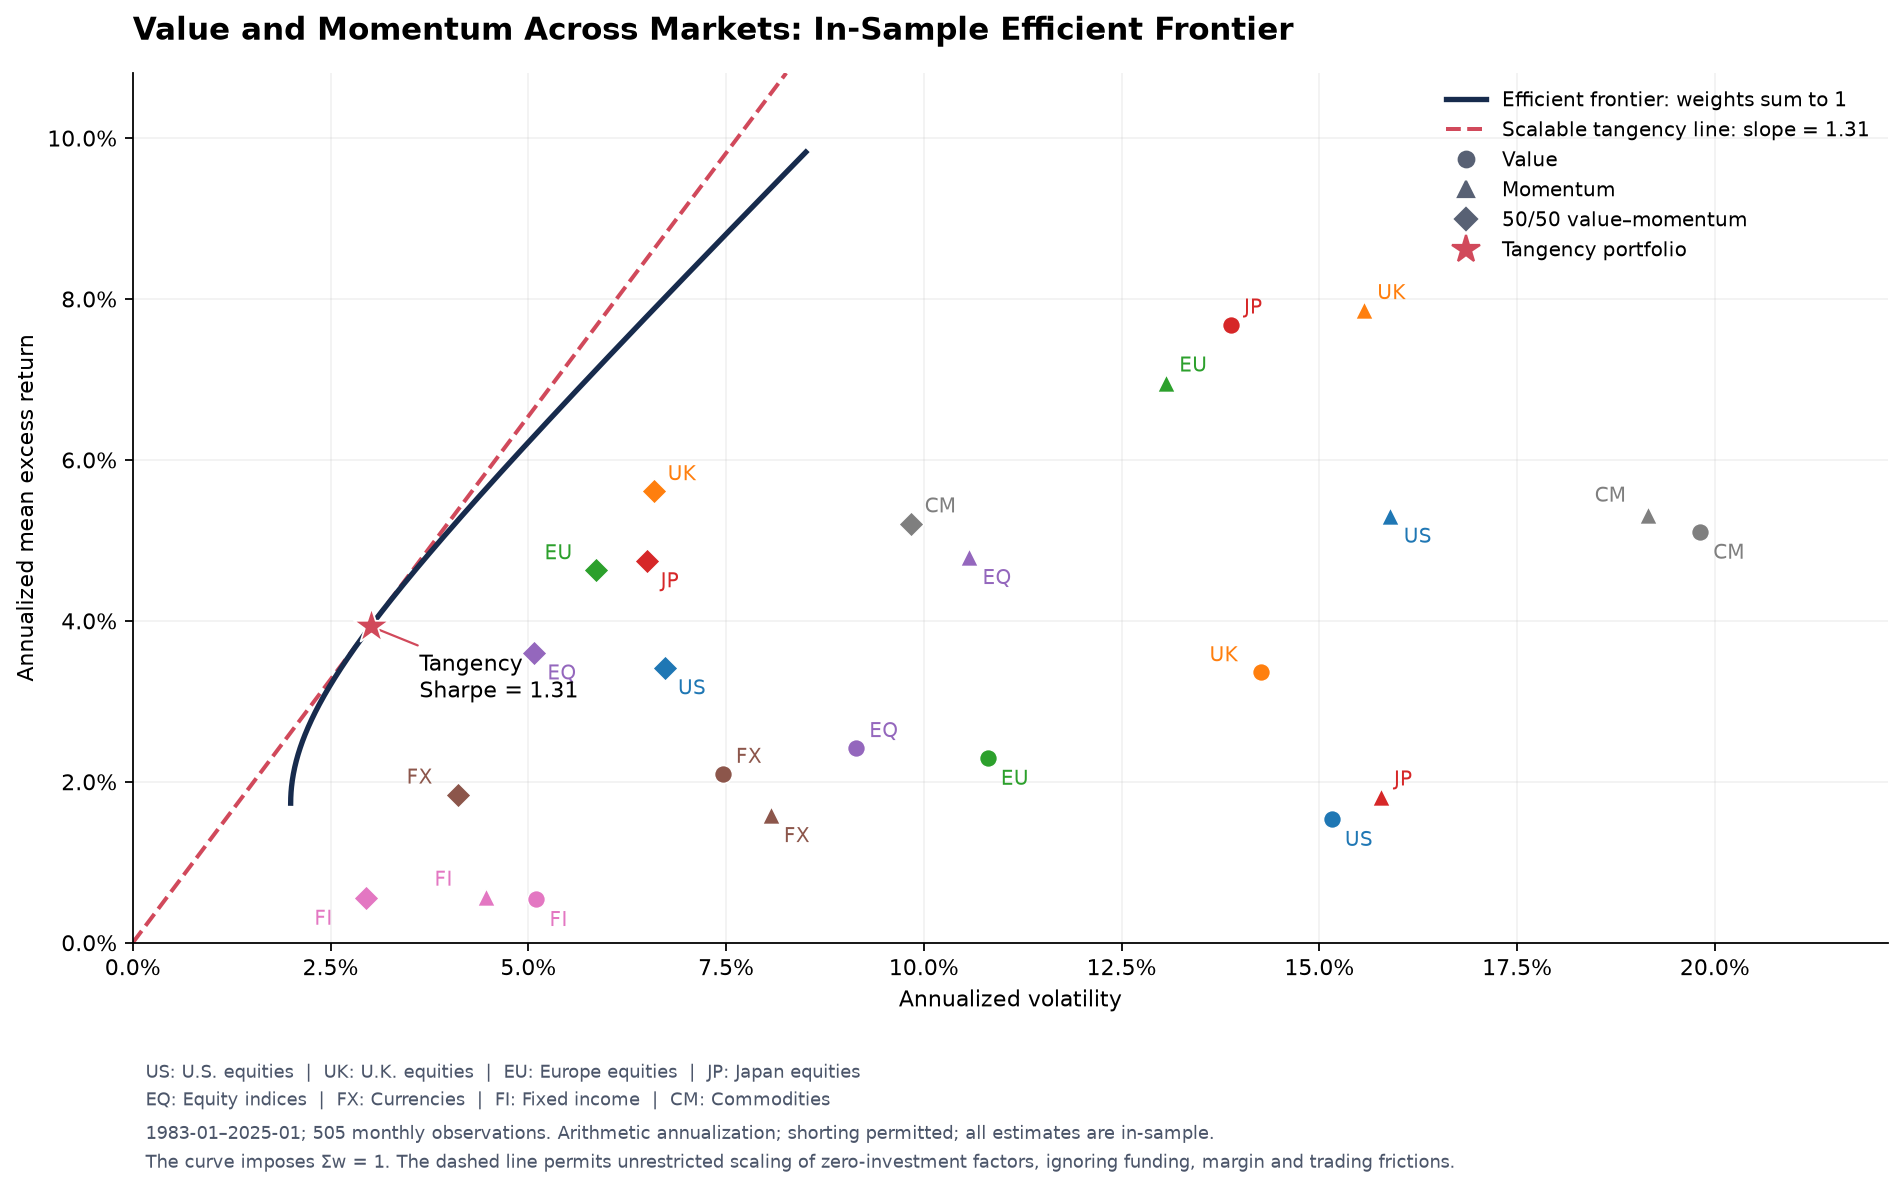

In [5]:
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False
})

fig, ax = plt.subplots(figsize=(12, 7.5), dpi=160)
tx, ty = summary.loc["Tangency", ["Annual volatility", "Annual mean"]]
sr = ty / tx
ymax = 1.10 * frontier_mean.max()
line_vol = np.linspace(0, ymax / sr, 300)

ax.plot(frontier_vol, frontier_mean, color="#172B4D", lw=2.4, zorder=3)
ax.plot(line_vol, sr * line_vol, color="#D1495B", ls="--", lw=1.8, zorder=2)
assert np.isclose(sr * tx, ty)

colors = dict(zip(markets, plt.get_cmap("tab10").colors[:8]))
offsets = {
    "VAL^US": (6, -12), "MOM^US": (6, -12),
    "VAL^UK": (-23, 5), "MOM^UK": (6, 5),
    "VAL^EU": (6, -12), "MOM^EU": (6, 5),
    "VAL^JP": (6, 5), "MOM^JP": (6, 5),
    "VAL^EQ": (6, 5), "MOM^EQ": (6, -12),
    "VAL^FX": (6, 5), "MOM^FX": (6, -12),
    "VAL^FI": (6, -12), "MOM^FI": (-23, 5),
    "VAL^CM": (6, -12), "MOM^CM": (-24, 6),
    "50/50 US": (6, -12), "50/50 UK": (6, 5),
    "50/50 EU": (-23, 5), "50/50 JP": (6, -12),
    "50/50 EQ": (6, -12), "50/50 FX": (-23, 5),
    "50/50 FI": (-23, -12), "50/50 CM": (6, 5)
}

for k in markets:
    for name, marker in (
        (f"VAL^{k}", "o"), (f"MOM^{k}", "^"), (f"50/50 {k}", "D")
    ):
        x, y = summary.loc[name, ["Annual volatility", "Annual mean"]]
        ax.scatter(
            x, y, marker=marker, s=65, color=colors[k],
            edgecolor="white", linewidth=0.7, zorder=4
        )
        ax.annotate(
            k, (x, y), xytext=offsets[name], textcoords="offset points",
            color=colors[k], fontsize=9
        )

ax.scatter(
    tx, ty, marker="*", s=280, color="#D1495B",
    edgecolor="white", linewidth=0.8, zorder=6
)
ax.annotate(
    f"Tangency\nSharpe = {sr:.2f}", (tx, ty),
    xytext=(22, -32), textcoords="offset points", fontsize=10,
    arrowprops={"arrowstyle": "-", "color": "#D1495B"}
)

handles = [
    Line2D([], [], color="#172B4D", lw=2.4,
           label="Efficient frontier: weights sum to 1"),
    Line2D([], [], color="#D1495B", ls="--", lw=1.8,
           label=f"Scalable tangency line: slope = {sr:.2f}"),
    *[
        Line2D([], [], ls="", marker=marker, color="#586174",
               markersize=7, label=label)
        for marker, label in (
            ("o", "Value"), ("^", "Momentum"), ("D", "50/50 value–momentum")
        )
    ],
    Line2D([], [], ls="", marker="*", color="#D1495B",
           markersize=13, label="Tangency portfolio")
]
ax.legend(handles=handles, loc="upper right", frameon=False, fontsize=9)
ax.set(
    xlabel="Annualized volatility",
    ylabel="Annualized mean excess return",
    xlim=(0, 1.12 * summary["Annual volatility"].max()),
    ylim=(0, ymax)
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.16)
ax.set_title(
    "Value and Momentum Across Markets: In-Sample Efficient Frontier",
    loc="left", fontsize=14, weight="bold", pad=15
)

key = [f"{k}: {name}" for k, name in markets.items()]
fig.text(0.08, 0.095, "  |  ".join(key[:4]), fontsize=8, color="#4C566A")
fig.text(0.08, 0.072, "  |  ".join(key[4:]), fontsize=8, color="#4C566A")
fig.text(
    0.08, 0.044,
    f"{R.index[0]}–{R.index[-1]}; {T} monthly observations. "
    "Arithmetic annualization; shorting permitted; all estimates are in-sample.",
    fontsize=8, color="#4C566A"
)
fig.text(
    0.08, 0.020,
    "The curve imposes Σw = 1. The dashed line permits unrestricted scaling "
    "of zero-investment factors, ignoring funding, margin and trading frictions.",
    fontsize=8, color="#4C566A"
)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.show()

In [9]:


corr = R.corr()
within_corr = pd.Series({
    k: corr.loc[f"VAL^{k}", f"MOM^{k}"] for k in markets
}, name="Value–momentum correlation")

fi_cross = corr.loc[
    "VAL^FI", [c for c in cols if not c.endswith("^FI")]
]
w = pd.Series(w_tan, index=cols)
largest = w.nlargest(4)
best_single = summary.loc[cols, "Annual Sharpe"].idxmax()
best_combo = summary.loc[combos.columns, "Annual Sharpe"].idxmax()
value_heavier = sum(w[f"VAL^{k}"] > w[f"MOM^{k}"] for k in markets)

display(pd.DataFrame({
    "Market": pd.Series(markets),
    "Value–momentum correlation": within_corr.map("{:.3f}".format)
}))



,Market,Value–momentum correlation
US,U.S. equities,-0.626
UK,U.K. equities,-0.612
EU,Europe equities,-0.533
JP,Japan equities,-0.622
EQ,Equity indices,-0.478
FX,Currencies,-0.442
FI,Fixed income,-0.248
CM,Commodities,-0.490


The tangency portfolio includes all eight markets. Only U.S. value (−3.14%) and U.S. momentum (−0.36%) have negative weights. The absolute factor weights sum to 1.07.

The largest weights go to Japan value (12.38%), currency value (11.96%), equity-index value (11.86%), and fixed-income value (11.29%). Fixed-income value has a low standalone Sharpe ratio of 0.11. It still receives a large weight because its low volatility and low correlations with other factors help reduce portfolio risk.

Value receives more weight than momentum in five of the eight markets. Within each market, their correlations range from −0.63 to −0.25. Combining them therefore provides diversification benefits.

The tangency portfolio has an annualized mean return of 3.93%, volatility of 3.01%, and Sharpe ratio of 1.31. The best individual factor, Japan value, has a Sharpe ratio of 0.55. The best 50/50 combination, U.K. value and momentum, reaches 0.85. These results use the same data to estimate and evaluate the weights. Part (i) checks how well the weights perform on held-out observations.

The curved frontier requires weights to sum to one. If factor positions can be scaled freely without costs or funding limits, the efficient set becomes a straight line from the origin through the tangency portfolio. Its slope is 1.31. The curve touches this line at the tangency point.

In [10]:

illustrative_predicted_drop = 0.25
print("Illustrative prediction (not preregistered): a 25% lower held-out Sharpe.")

assert R.columns.tolist() == cols and R.shape == (T, N)
assert isinstance(R.index, pd.PeriodIndex) and R.index.freqstr == "M"
assert R.index.is_unique and R.index.is_monotonic_increasing
assert np.isfinite(R.to_numpy()).all()

even = R.index.month % 2 == 0
assert even.sum() > N and (~even).sum() > N

oos_returns = pd.Series(np.nan, index=R.index, name="Cross-fitted OOS")
assigned = pd.Series(0, index=R.index)
fold_weights, split_checks = {}, []

for label, train in [("Even → odd", even), ("Odd → even", ~even)]:
    training, held_out = R.loc[train], R.loc[~train]
    assert training.index.intersection(held_out.index).empty
    assert training.index.union(held_out.index).sort_values().equals(R.index)

    train_mu = training.mean().to_numpy()
    train_cov = training.cov(ddof=1).to_numpy()
    assert np.linalg.eigvalsh(train_cov).min() > 0

    direction = np.linalg.solve(train_cov, train_mu)
    assert direction.sum() > 0
    fold_w = pd.Series(direction / direction.sum(), index=R.columns)
    assert np.isfinite(fold_w).all() and np.isclose(fold_w.sum(), 1)

    predicted = held_out @ fold_w
    assert predicted.index.equals(held_out.index)
    oos_returns.loc[held_out.index] = predicted
    assigned.loc[held_out.index] += 1
    fold_weights[label] = fold_w
    split_checks.append([
        label, len(training), len(held_out), (fold_w < 0).sum()
    ])

assert assigned.eq(1).all() and oos_returns.notna().all()
assert oos_returns.index.equals(tangency_returns.index)
assert np.allclose(tangency_returns, R @ w_tan)

display(pd.DataFrame(split_checks, columns=[
    "Train → test", "Training months", "Held-out months", "Negative weights"
]).set_index("Train → test"))

display(pd.DataFrame({
    "Full-sample": pd.Series(w_tan, index=R.columns), **fold_weights
}).apply(lambda s: s.map("{:.2%}".format)))

Illustrative prediction (not preregistered): a 25% lower held-out Sharpe.


,Training months,Held-out months,Negative weights
Train → test,,,
Even → odd,252,253,3
Odd → even,253,252,5


,Full-sample,Even → odd,Odd → even
VAL^US,-3.14%,-4.72%,5.00%
MOM^US,-0.36%,6.12%,-5.44%
VAL^UK,6.37%,-1.82%,10.70%
MOM^UK,8.61%,-3.37%,14.90%
VAL^EU,3.91%,6.01%,-0.01%
MOM^EU,5.18%,3.78%,9.06%
VAL^JP,12.38%,20.86%,-0.57%
MOM^JP,4.97%,7.21%,-1.41%
VAL^EQ,11.86%,6.54%,14.68%
MOM^EQ,9.60%,2.22%,15.30%


## Question (i)

In [11]:

evaluated_returns = pd.concat([
    tangency_returns.rename("In-sample"), oos_returns
], axis=1)

comparison = pd.DataFrame({
    "Monthly mean": evaluated_returns.mean(),
    "Monthly volatility": evaluated_returns.std(ddof=1),
    "Annual mean": ANN * evaluated_returns.mean(),
    "Annual volatility": np.sqrt(ANN) * evaluated_returns.std(ddof=1)
})
comparison["Annual Sharpe"] = (
    comparison["Annual mean"] / comparison["Annual volatility"]
)
comparison.loc["OOS − IS"] = (
    comparison.loc["Cross-fitted OOS"] - comparison.loc["In-sample"]
)

display(comparison.apply(lambda s: s.map(
    "{:.3f}".format if s.name == "Annual Sharpe" else "{:.3%}".format
)))

is_mean, is_vol, is_sr = comparison.loc[
    "In-sample", ["Annual mean", "Annual volatility", "Annual Sharpe"]
]
oos_mean, oos_vol, oos_sr = comparison.loc[
    "Cross-fitted OOS", ["Annual mean", "Annual volatility", "Annual Sharpe"]
]

sr_drop = 1 - oos_sr / is_sr
print(f"Annual mean decreases by {100*(is_mean-oos_mean):.2f} percentage points.")
print(f"Annual volatility increases by {100*(oos_vol-is_vol):.2f} percentage points.")
print(f"Sharpe decreases by {is_sr-oos_sr:.3f}, or {sr_drop:.1%}.")
print(f"Observed versus illustrative predicted Sharpe decline: "
      f"{sr_drop:.1%} versus {illustrative_predicted_drop:.0%}.")

radicand = D * (A * oos_vol**2 / ANN - 1)
assert radicand >= 0, "OOS volatility is below the fixed-weight frontier minimum."
frontier_mean_at_oos_vol = ANN * (B + np.sqrt(radicand)) / A
frontier_gap = frontier_mean_at_oos_vol - oos_mean

display(pd.DataFrame({
    "Annual volatility": [oos_vol, oos_vol],
    "Annual mean": [frontier_mean_at_oos_vol, oos_mean]
}, index=["Ex post frontier at OOS volatility", "Cross-fitted OOS"])
        .apply(lambda s: s.map("{:.3%}".format)))

print(f"At the same volatility, OOS mean is {100*frontier_gap:.2f} "
      "percentage points below the ex post frontier.")

,Monthly mean,Monthly volatility,Annual mean,Annual volatility,Annual Sharpe
In-sample,0.328%,0.868%,3.932%,3.005%,1.308
Cross-fitted OOS,0.182%,1.025%,2.187%,3.552%,0.616
OOS − IS,-0.145%,0.158%,-1.745%,0.547%,-0.693


Annual mean decreases by 1.75 percentage points.
Annual volatility increases by 0.55 percentage points.
Sharpe decreases by 0.693, or 52.9%.
Observed versus illustrative predicted Sharpe decline: 52.9% versus 25%.


,Annual volatility,Annual mean
Ex post frontier at OOS volatility,3.552%,4.608%
Cross-fitted OOS,3.552%,2.187%


At the same volatility, OOS mean is 2.42 percentage points below the ex post frontier.


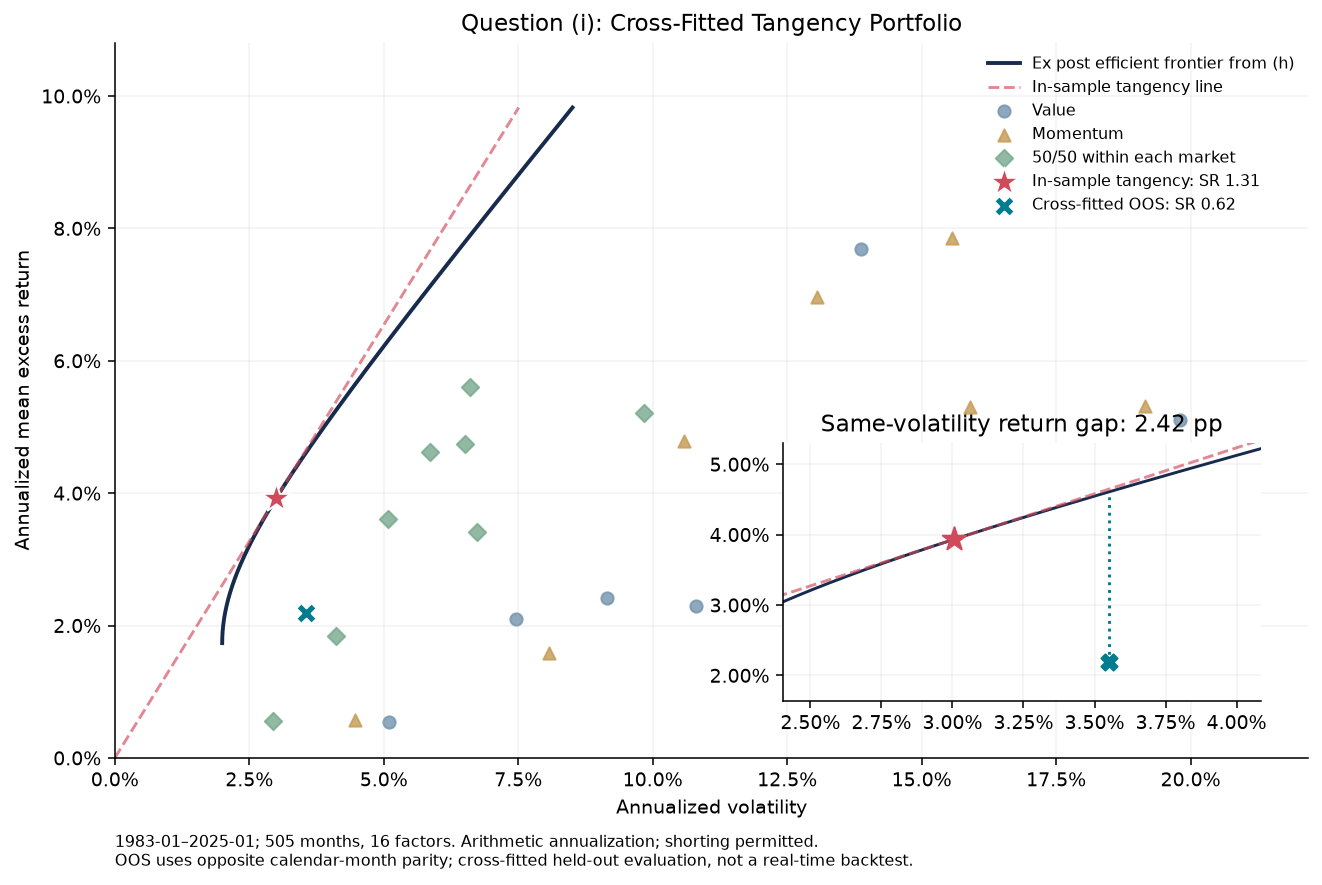

In [ ]:

fig_i, ax_i = plt.subplots(figsize=(11, 7), dpi=140)

ax_i.plot(frontier_vol, frontier_mean, color="#172B4D", lw=2,
          label="Ex post efficient frontier from (h)")
line_x = np.linspace(0, frontier_mean.max() / is_sr, 200)
ax_i.plot(line_x, is_sr * line_x, "--", color="#D1495B", alpha=0.65,
          label="In-sample tangency line")

for names, marker, color, label in [
    ([c for c in cols if c.startswith("VAL")], "o", "#7293AD", "Value"),
    ([c for c in cols if c.startswith("MOM")], "^", "#C49A52", "Momentum"),
    (list(combos.columns), "D", "#77A88C", "50/50 within each market")
]:
    ax_i.scatter(
        summary.loc[names, "Annual volatility"],
        summary.loc[names, "Annual mean"],
        marker=marker, color=color, s=40, alpha=0.8, label=label
    )

ax_i.scatter(is_vol, is_mean, marker="*", s=240, color="#D1495B",
             edgecolor="white", zorder=5,
             label=f"In-sample tangency: SR {is_sr:.2f}")
ax_i.scatter(oos_vol, oos_mean, marker="X", s=110, color="#007C91",
             edgecolor="white", zorder=6,
             label=f"Cross-fitted OOS: SR {oos_sr:.2f}")

zoom = ax_i.inset_axes([0.56, 0.08, 0.40, 0.36])
zoom.plot(frontier_vol, frontier_mean, color="#172B4D", lw=1.5)
zoom.plot(line_x, is_sr * line_x, "--", color="#D1495B", alpha=0.65)
zoom.scatter(is_vol, is_mean, marker="*", s=160, color="#D1495B", zorder=5)
zoom.scatter(oos_vol, oos_mean, marker="X", s=70, color="#007C91", zorder=5)
zoom.plot([oos_vol, oos_vol], [oos_mean, frontier_mean_at_oos_vol],
          ":", color="#007C91")
zoom.set(
    xlim=(0.80 * min(is_vol, oos_vol), 1.15 * max(is_vol, oos_vol)),
    ylim=(0.75 * min(is_mean, oos_mean),
          1.15 * max(is_mean, oos_mean, frontier_mean_at_oos_vol)),
    title=f"Same-volatility return gap: {100*frontier_gap:.2f} pp"
)

ax_i.set(
    xlabel="Annualized volatility",
    ylabel="Annualized mean excess return",
    title="Question (i): Cross-Fitted Tangency Portfolio",
    xlim=(0, 1.12 * summary["Annual volatility"].max()),
    ylim=(0, 1.10 * frontier_mean.max())
)
for axis in (ax_i, zoom):
    axis.xaxis.set_major_formatter(PercentFormatter(1))
    axis.yaxis.set_major_formatter(PercentFormatter(1))
    axis.grid(alpha=0.16)

ax_i.legend(loc="upper right", fontsize=8, frameon=False)
fig_i.subplots_adjust(bottom=0.15)
fig_i.text(
    0.125, 0.04,
    f"{R.index[0]}–{R.index[-1]}; {T} months, {N} factors. "
    "Arithmetic annualization; shorting permitted.\n"
    "OOS uses opposite calendar-month parity; cross-fitted held-out evaluation, "
    "not a real-time backtest.",
    fontsize=8
)
plt.show()

### AI intergration

#### My prediction: I expect the out-of-sample tangency portfolio's Sharpe ratio to be around 20% to 40% lower than its in-sample Sharpe ratio. The in-sample portfolio maximizes the Sharpe ratio using estimated means and covariances, which contain sampling errors. With many value and momentum factors, the optimization can overfit historical noise and produce extreme portfolio weights. When these weights are applied to held-out months, performance is likely to deteriorate. The even/odd-month split should provide a more realistic estimate of performance, although it is not a real-time backtest.

#### LLM Answer:

The in-sample tangency portfolio tends to overstate the achievable Sharpe ratio because of estimation error and overfitting. The portfolio weights are optimized using historical sample means and covariances, which contain noise. The optimization process can exploit this noise, assigning large weights to factors that performed well by chance. As a result, the in-sample Sharpe ratio reflects both genuine return predictability and favorable random variation.

Splitting the sample provides a more honest estimate because portfolio weights are estimated using one subset of months and evaluated on different, held-out months. The portfolio cannot directly exploit the random noise in the evaluation sample. This better approximates how the strategy would perform on unseen data.

Therefore, we expect the out-of-sample Sharpe ratio to be lower than the in-sample Sharpe ratio, especially when many factors are optimized using limited historical data. However, even/odd-month testing is not fully equivalent to a real-time backtest because the training months may include observations from after the evaluation months.

(i) Yes. The LLM correctly explains that in-sample tangency optimization uses estimated means and covariances that contain sampling error. The optimizer can fit noise rather than genuine return patterns, leading to an overstated Sharpe ratio. It also recognizes that overfitting becomes more severe when more factors are optimized using limited historical data.

(ii) No. The LLM explains the mechanism of estimation error but never connects it to the Roll critique or to PS3/PS4. It misses the key point: the in-sample tangency portfolio is mean-variance efficient by construction. Used as a single factor, it prices all 16 test assets exactly; we confirmed every alpha is zero up to rounding (max |α| ≈ 10⁻¹⁷). That means GRS = 0, and Fama-MacBeth betas on it fit average returns perfectly. As Roll argued, such a test has no power, so in-sample optimality says nothing about the economics or about achievable performance. Only held-out evaluation, as in part (i), is informative.

(iii) The cross-fitted portfolio falls well inside the in-sample frontier. Its Sharpe ratio is 0.62 versus 1.31 (−53%), and at the same 3.55% volatility it earns 2.42 percentage points less than the frontier (2.19% vs 4.61%). Both folds degrade similarly (0.71 and 0.52 out of sample, versus 1.44 and 1.72 in sample). This matches the LLM’s direction: 16 factors estimated on about 252 months per half leaves a lot of room to fit noise. But the LLM gave no magnitude, and our own 20–40% prediction underestimated the actual 53% decline. Most of the in-sample Sharpe advantage of the tangency portfolio does not survive held-out evaluation. The out-of-sample Sharpe of 0.62 is still above every single factor (best 0.55) but below the best 50/50 combination (0.85).

(iv) Yes. The LLM correctly notes that the even/odd split is not a real-time backtest, because the training half contains months that come after the evaluated months. It does not loosely call it a real-time test. However, it understates the implication. The method is a cross-fitted, held-out estimate: each month is scored with weights it did not help estimate, but those weights use future information an investor would not have had. It also assumes means and covariances are stable over 1983–2025, and adjacent months fall in opposite halves, so persistent regimes leak across the split. Our out-of-sample Sharpe of 0.62 is therefore best read as an upper bound on what a chronological, expanding-window backtest would deliver.

## Question (k)

In [24]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import t as student_t
from IPython.display import display

markets_k = {
    "US": "U.S. equities", "UK": "U.K. equities", "EU": "Europe equities",
    "JP": "Japan equities", "EQ": "Equity indices", "FX": "Currencies",
    "FI": "Fixed income", "CM": "Commodities"
}
cols_k = [f"{s}^{m}" for m in markets_k for s in ("VAL", "MOM")]

if "R" in globals():
    R_k = R.copy()
else:
    files_k = sorted(
        p for root in (Path.cwd(), Path.cwd() / "upload")
        for p in root.glob("Problem_Set9_2026*.xls*")
        if p.suffix.lower() in (".xls", ".xlsx")
    )
    if not files_k:
        raise FileNotFoundError("Place Problem_Set9_2026.xls or .xlsx beside this notebook.")

    raw_k = pd.read_excel(
        files_k[0], sheet_name="Value and momentum factors", header=4,
        na_values=["NA", "N/A", -999, -99.99, -9999]
    )
    assert raw_k.columns.tolist() == ["DATE"] + cols_k
    dates_k = pd.to_datetime(raw_k.pop("DATE"), errors="raise").dt.to_period("M")
    assert dates_k.notna().all() and not dates_k.duplicated().any()
    raw_k.index = pd.PeriodIndex(dates_k, name="Month")
    R_k = (
        raw_k.apply(pd.to_numeric, errors="raise")
        .replace([np.inf, -np.inf], np.nan)
        .sort_index().dropna(how="any").copy()
    )

assert R_k.columns.tolist() == cols_k
assert isinstance(R_k.index, pd.PeriodIndex)
assert R_k.index.is_unique and R_k.index.is_monotonic_increasing
assert R_k.index.equals(pd.period_range("1983-01", "2025-01", freq="M"))
assert R_k.shape == (505, 16) and np.isfinite(R_k.to_numpy()).all()

print(f"Sample: {R_k.index[0]}–{R_k.index[-1]}; {len(R_k)} months, 16 factors.")
print("Monthly decimal returns, as in (h): 0.01 = 1%; no RF subtraction.")

Sample: 1983-01–2025-01; 505 months, 16 factors.
Monthly decimal returns, as in (h): 0.01 = 1%; no RF subtraction.


In [25]:

vol_k = R_k.std(ddof=1)
assert vol_k.gt(0).all()

weights_k, factors_k = {}, {}

for market in markets_k:
    W = pd.DataFrame(0.0, index=cols_k, columns=["VAL_other", "MOM_other"])

    for style in ("VAL", "MOM"):
        eligible = [f"{style}^{m}" for m in markets_k if m != market]
        inv_vol = 1 / vol_k.loc[eligible]
        W.loc[eligible, f"{style}_other"] = inv_vol / inv_vol.sum()

        assert len(eligible) == 7
        assert all(c.split("^")[1] != market for c in eligible)
        assert W[f"{style}_other"].gt(0).sum() == 7

    assert W.ge(0).all().all() and np.allclose(W.sum(), 1)
    assert W.loc[[f"VAL^{market}", f"MOM^{market}"]].eq(0).all().all()

    weights_k[market] = W
    factors_k[market] = R_k @ W

    assert factors_k[market].index.equals(R_k.index)
    assert np.isfinite(factors_k[market].to_numpy()).all()

print("Validated all eight exclusions: both target-market factors have zero weight.")
print("Each predictor averages seven same-style factors with positive weights summing to one.")
print("Weights use fixed full-sample standard deviations; this is an in-sample analysis.")

Validated all eight exclusions: both target-market factors have zero weight.
Each predictor averages seven same-style factors with positive weights summing to one.
Weights use fixed full-sample standard deviations; this is an in-sample analysis.


In [ ]:

HAC_LAGS_k = 6

def fit_k(y, F):
    assert y.index.equals(F.index)
    X = np.column_stack([np.ones(len(y)), F.to_numpy()])
    n, p = X.shape
    assert np.linalg.matrix_rank(X) == p and n > p + HAC_LAGS_k

    b = np.linalg.lstsq(X, y.to_numpy(), rcond=None)[0]
    e = y.to_numpy() - X @ b
    bread = np.linalg.inv(X.T @ X)
    cov_ols = (e @ e) / (n - p) * bread

    scores = X * e[:, None]
    meat = scores.T @ scores
    for lag in range(1, HAC_LAGS_k + 1):
        cross = scores[lag:].T @ scores[:-lag]
        meat += (1 - lag / (HAC_LAGS_k + 1)) * (cross + cross.T)
    cov_hac = n / (n - p) * bread @ meat @ bread

    t_ols = b[0] / np.sqrt(cov_ols[0, 0])
    t_hac = b[0] / np.sqrt(cov_hac[0, 0])
    actual = y.mean()
    predicted = F.mean().to_numpy() @ b[1:]

    assert np.isclose(actual - predicted, b[0], rtol=1e-8, atol=1e-12)

    return {
        "Alpha": b[0],
        "t(alpha), OLS": t_ols,
        "p(alpha), OLS": 2 * student_t.sf(abs(t_ols), n - p),
        "t(alpha), HAC": t_hac,
        "p(alpha), HAC": 2 * student_t.sf(abs(t_hac), n - p),
        "R2": 1 - (e @ e) / np.sum((y - actual) ** 2),
        "Beta VAL": b[1],
        "Beta MOM": b[2],
        "Actual mean": actual,
        "Predicted mean": predicted
    }

results_k = pd.DataFrame({
    c: fit_k(R_k[c], factors_k[c.split("^")[1]]) for c in cols_k
}).T
results_k.index.name = "Portfolio"

assert results_k.shape == (16, 10)
assert np.isfinite(results_k.to_numpy()).all()
assert np.allclose(
    results_k["Actual mean"] - results_k["Predicted mean"],
    results_k["Alpha"]
)

formats_k = {c: "{:.3f}" for c in results_k.columns}
formats_k.update({
    "Alpha": "{:.3%}", "Actual mean": "{:.3%}", "Predicted mean": "{:.3%}",
    "R2": "{:.1%}", "p(alpha), OLS": "{:.4f}", "p(alpha), HAC": "{:.4f}"
})
display(results_k.style.format(formats_k))

print("Alpha and means are monthly; predicted mean = beta_VAL × mean(VAL_other)"
      " + beta_MOM × mean(MOM_other), excluding the intercept.")
print("HAC uses six lags, Bartlett weights, and a finite-sample covariance adjustment.")
print("OLS p-values use t(502); HAC p-values use the same reference as an approximation.")

,Alpha,"t(alpha), OLS","p(alpha), OLS","t(alpha), HAC","p(alpha), HAC",R2,Beta VAL,Beta MOM,Actual mean,Predicted mean
Portfolio,,,,,,,,,,
VAL^US,-0.266%,-1.572,0.1165,-1.527,0.1273,32.5%,1.736,0.049,0.128%,0.394%
MOM^US,0.205%,1.230,0.2192,1.073,0.2837,41.0%,-0.574,1.382,0.442%,0.237%
VAL^UK,-0.081%,-0.556,0.5787,-0.526,0.5994,42.6%,1.821,-0.052,0.280%,0.361%
MOM^UK,0.382%,2.533,0.0116,2.646,0.0084,48.6%,-0.517,1.559,0.655%,0.273%
VAL^EU,-0.081%,-0.787,0.4315,-0.699,0.4846,50.1%,1.408,-0.122,0.191%,0.273%
MOM^EU,0.242%,2.033,0.0426,1.890,0.0594,54.7%,-0.182,1.544,0.580%,0.338%
VAL^JP,0.385%,2.276,0.0233,1.926,0.0547,18.5%,1.236,0.160,0.640%,0.255%
MOM^JP,-0.043%,-0.217,0.8287,-0.222,0.8247,14.6%,-0.256,0.820,0.151%,0.194%
VAL^EQ,0.165%,1.432,0.1528,1.267,0.2058,12.4%,0.406,-0.193,0.201%,0.036%


Alpha and means are monthly; predicted mean = beta_VAL × mean(VAL_other) + beta_MOM × mean(MOM_other), excluding the intercept.
HAC uses six lags, Bartlett weights, and a finite-sample covariance adjustment.
OLS p-values use t(502); HAC p-values use the same reference as an approximation.


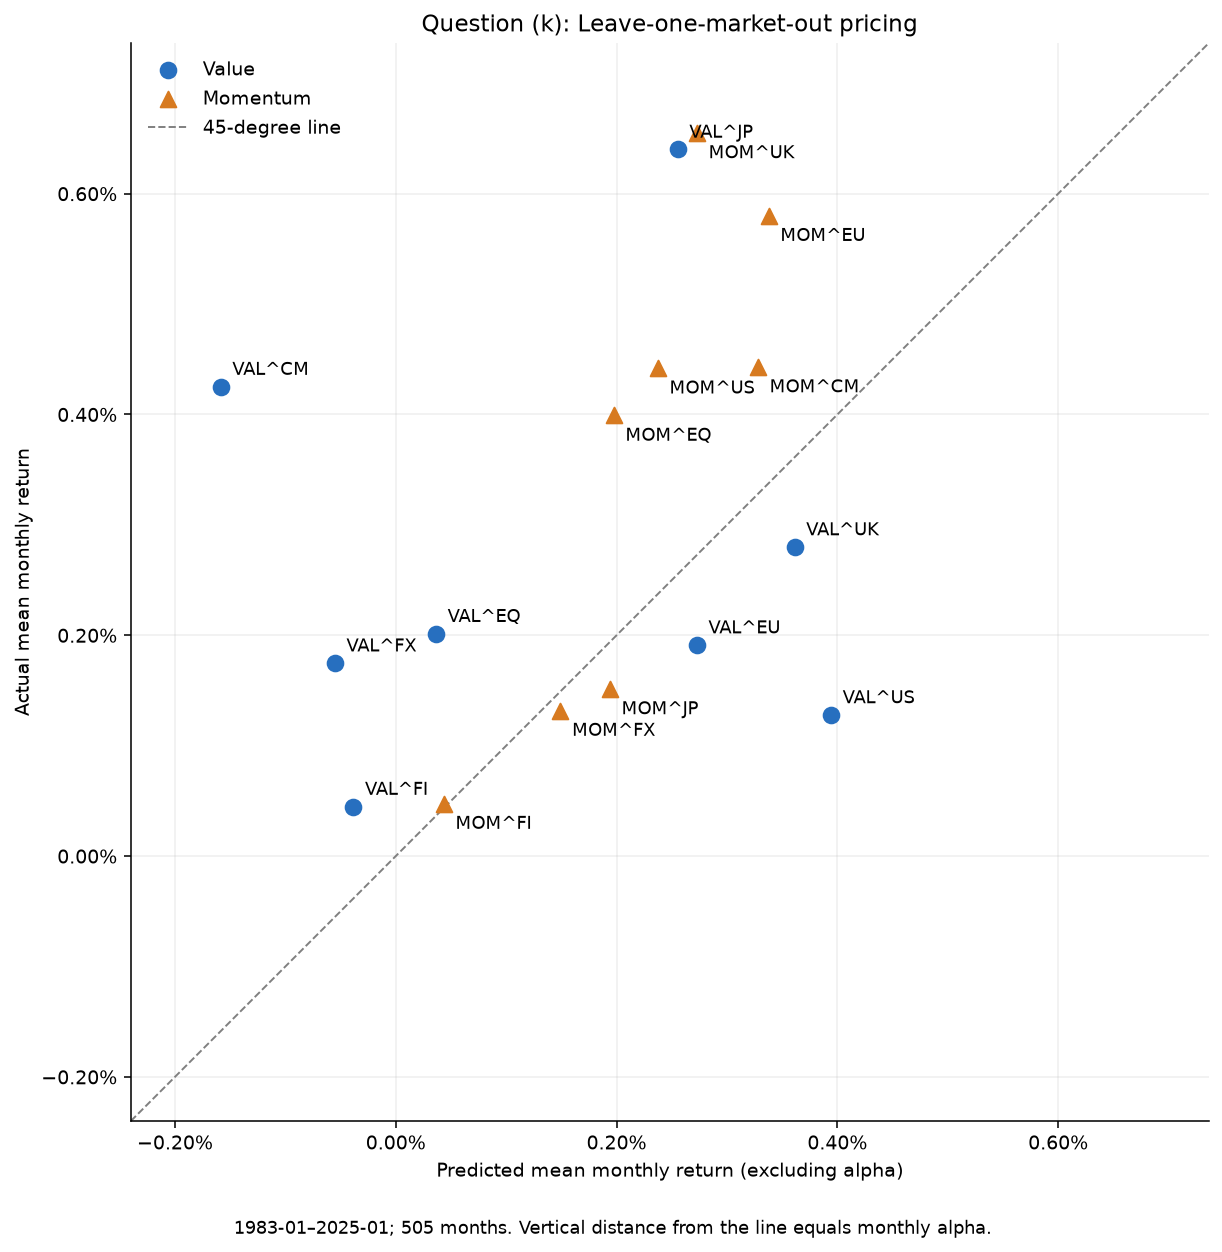

In [ ]:

fig_k, ax_k = plt.subplots(figsize=(9, 9), dpi=140)

for style, marker, color, label in [
    ("VAL", "o", "#276FBF", "Value"),
    ("MOM", "^", "#D77A20", "Momentum")
]:
    names = [c for c in cols_k if c.startswith(style)]
    ax_k.scatter(
        results_k.loc[names, "Predicted mean"],
        results_k.loc[names, "Actual mean"],
        s=65, marker=marker, color=color, label=label, zorder=3
    )

for i, (name, row) in enumerate(results_k.iterrows()):
    ax_k.annotate(
        name, (row["Predicted mean"], row["Actual mean"]),
        xytext=(6, 6 if i % 2 == 0 else -13),
        textcoords="offset points", fontsize=9
    )

values_k = results_k[["Actual mean", "Predicted mean"]].to_numpy()
padding_k = 0.10 * np.ptp(values_k)
limits_k = (values_k.min() - padding_k, values_k.max() + padding_k)

ax_k.plot(limits_k, limits_k, "--", color="gray", lw=1, label="45-degree line")
ax_k.set(
    xlim=limits_k, ylim=limits_k,
    xlabel="Predicted mean monthly return (excluding alpha)",
    ylabel="Actual mean monthly return",
    title="Question (k): Leave-one-market-out pricing"
)
ax_k.set_aspect("equal", adjustable="box")
ax_k.xaxis.set_major_formatter(PercentFormatter(1))
ax_k.yaxis.set_major_formatter(PercentFormatter(1))
ax_k.legend(frameon=False)
ax_k.grid(alpha=0.2)

fig_k.text(
    0.5, 0.015,
    f"{R_k.index[0]}–{R_k.index[-1]}; {len(R_k)} months. "
    "Vertical distance from the line equals monthly alpha.",
    ha="center", fontsize=9
)
fig_k.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

No. The standard GRS F-test requires all test portfolios to use the same factor returns. In question (k), each market uses different predictors because its own factors are excluded. This breaks the common-factor structure required by GRS.

The plot’s vertical gaps from the 45-degree line show estimated alphas. They do not establish joint statistical significance.

### Question (I)

In [29]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import f as f_dist, t as t_dist
from IPython.display import display

files_l = [
    root / name
    for root in (Path.cwd(), Path.cwd() / "upload")
    for name in ("Problem_Set9_2026(5).xlsx", "Problem_Set9_2026.xlsx",
                 "Problem_Set9_2026.xls")
]
files_l += sorted(
    p for root in (Path.cwd(), Path.cwd() / "upload")
    for p in root.glob("Problem_Set9_2026*.xls*")
    if p.suffix.lower() in (".xls", ".xlsx")
)
file_l = next((p for p in files_l if p.is_file()), None)
if file_l is None:
    raise FileNotFoundError("Place the Problem_Set9_2026 workbook beside this notebook.")

na_l = ["NA", "N/A", -999, -99.99, -9999]
cols_l = [
    f"{s}^{m}"
    for m in ("US", "UK", "EU", "JP", "EQ", "FX", "FI", "CM")
    for s in ("VAL", "MOM")
]

def read_l(sheet, header, date_column, date_format=None):
    d = pd.read_excel(file_l, sheet_name=sheet, header=header, na_values=na_l)
    dates = d.pop(date_column)
    if date_format:
        dates = dates.astype("int64").astype(str)
    dates = pd.to_datetime(dates, format=date_format, errors="raise")
    d.index = pd.PeriodIndex(dates.dt.to_period("M"), name="Month")
    assert d.index.notna().all() and d.index.is_unique
    return (
        d.apply(pd.to_numeric, errors="raise")
        .replace([np.inf, -np.inf], np.nan).sort_index()
    )

raw_l = read_l("Value and momentum factors", 4, "DATE")
assert raw_l.columns.tolist() == cols_l
clean_l = raw_l.dropna().copy()
R_h_l = R.copy() if "R" in globals() else clean_l.copy()
pd.testing.assert_frame_equal(
    R_h_l, clean_l, check_names=False,
    check_exact=False, rtol=1e-10, atol=1e-12
)

ff_l = read_l("Fama-French factors", 0, "Unnamed: 0", "%Y%m")
ff_l = ff_l[["Mkt-RF", "SMB", "HML", "UMD", "LTREV", "STREV"]] / 100
ff_l = ff_l.rename(columns={"Mkt-RF": "RMRF", "STREV": "STR"})
amp_l = read_l("AMP factors", 3, "DATE", "%Y%m%d")[["VAL", "MOM"]]
amp_l = amp_l.rename(columns={"VAL": "VALeverywhere", "MOM": "MOMeverywhere"})
ts_l = read_l("TSMOM", 2, "DATE")[["TSMOM"]]
factors_l = pd.concat([ff_l, amp_l, ts_l], axis=1).reindex(R_h_l.index)

display(pd.DataFrame({
    "Missing within (h)": factors_l.isna().sum(),
    "Monthly volatility (%)": 100 * factors_l.std()
}).round(3))

print("Units: portfolio, AMP and TSMOM returns are stored as decimals.")
print("Fama-French returns are stored in percent and divided by 100.")
print("Aliases: Mkt-RF → RMRF; STREV → STR; AMP VAL/MOM → everywhere.")
print("All returns are long-short or excess returns; no RF subtraction.")

data_l = pd.concat([R_h_l, factors_l], axis=1).dropna()
Y_l, F_l = data_l[cols_l], data_l[factors_l.columns]
T_l, N_l = Y_l.shape

assert N_l == 16 and np.isfinite(data_l.to_numpy()).all()
assert data_l.index.equals(
    pd.period_range(data_l.index[0], data_l.index[-1], freq="M")
)
assert (F_l.std() > 0).all() and F_l.std().max() < 0.20

print(f"Common sample: {data_l.index[0]}–{data_l.index[-1]}; T={T_l}, N={N_l}.")
print(f"Excluded {len(R_h_l) - T_l} months from (h); identical dates in all models.")

,Missing within (h),Monthly volatility (%)
RMRF,0,4.460
SMB,0,3.001
HML,0,3.128
UMD,0,4.417
LTREV,0,2.642
STR,0,3.308
VALeverywhere,0,1.652
MOMeverywhere,0,1.971
TSMOM,24,3.638


Units: portfolio, AMP and TSMOM returns are stored as decimals.
Fama-French returns are stored in percent and divided by 100.
Aliases: Mkt-RF → RMRF; STREV → STR; AMP VAL/MOM → everywhere.
All returns are long-short or excess returns; no RF subtraction.
Common sample: 1985-01–2025-01; T=481, N=16.
Excluded 24 months from (h); identical dates in all models.


In [30]:

models_l = {
    "Model 1": ["RMRF"],
    "Model 2": ["RMRF", "SMB", "HML", "UMD"],
    "Model 3": ["RMRF", "VALeverywhere", "MOMeverywhere"],
    "Model 4": ["RMRF", "VALeverywhere", "MOMeverywhere", "TSMOM"],
    "Model 5": [
        "RMRF", "VALeverywhere", "MOMeverywhere", "TSMOM", "LTREV", "STR"
    ]
}

# Detect exact spanning before attempting any covariance inversion.
span_w_l = np.linalg.lstsq(
    Y_l, F_l[["VALeverywhere", "MOMeverywhere"]], rcond=None
)[0]
span_error_l = np.max(np.abs(
    F_l[["VALeverywhere", "MOMeverywhere"]].to_numpy()
    - Y_l.to_numpy() @ span_w_l
))
assert span_error_l < 1e-12
assert np.linalg.matrix_rank(span_w_l) == 2

drop_l = ["VAL^FI", "MOM^FI"]
drop_idx_l = [cols_l.index(c) for c in drop_l]
assert np.linalg.matrix_rank(span_w_l[drop_idx_l]) == 2

print(f"Everywhere-factor replication error: {span_error_l:.2e}.")
print("Two exact spanning relations make Models 3–5 residual covariances singular.")
print("Their standard 16-portfolio GRS statistics are undefined.")
print("Also report GRS tests of 14 independent restrictions, omitting "
      + ", ".join(drop_l) + ". The omitted alpha restrictions are redundant.")

Everywhere-factor replication error: 1.80e-16.
Two exact spanning relations make Models 3–5 residual covariances singular.
Their standard 16-portfolio GRS statistics are undefined.
Also report GRS tests of 14 independent restrictions, omitting VAL^FI, MOM^FI. The omitted alpha restrictions are redundant.


In [32]:
# Cell 3
def grs_l(y, factors):
    y, factors = np.asarray(y), np.asarray(factors)
    T, n = y.shape
    k = factors.shape[1]
    X = np.column_stack([np.ones(T), factors])

    assert T > n + k and np.linalg.matrix_rank(X) == k + 1
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b

    sigma_ml = e.T @ e / T
    fc = factors - factors.mean(axis=0)
    omega_ml = fc.T @ fc / T
    np.linalg.cholesky(sigma_ml)
    np.linalg.cholesky(omega_ml)

    alpha, mu = b[0], factors.mean(axis=0)
    sr_f2 = mu @ np.linalg.solve(omega_ml, mu)
    q = alpha @ np.linalg.solve(sigma_ml, alpha)
    stat = (T - n - k) / n * q / (1 + sr_f2)
    pvalue = f_dist.sf(stat, n, T - n - k)

    # Verify equivalent unbiased-covariance and Sharpe-ratio formulas.
    sigma_unbiased = e.T @ e / (T - k - 1)
    q_unbiased = alpha @ np.linalg.solve(sigma_unbiased, alpha)
    alt = (
        T * (T - n - k) / (n * (T - k - 1))
        * q_unbiased / (1 + sr_f2)
    )

    z = np.column_stack([factors, y])
    zc, zm = z - z.mean(axis=0), z.mean(axis=0)
    sr_joint2 = zm @ np.linalg.solve(zc.T @ zc / T, zm)
    sr_check = (T - n - k) / n * (sr_joint2 - sr_f2) / (1 + sr_f2)

    assert np.allclose(X.T @ e, 0, atol=1e-10)
    assert np.isclose(np.linalg.inv(X.T @ X)[0, 0], (1 + sr_f2) / T)
    assert np.allclose([alt, sr_check], stat, rtol=1e-9, atol=1e-10)
    assert stat >= 0 and 0 <= pvalue <= 1

    return stat, pvalue, max(abs(alt - stat), abs(sr_check - stat))

In [33]:

individual_l, comparison_l, tests_l, checks_l = {}, [], [], []

for name, names in models_l.items():
    factors = F_l[names].to_numpy()
    X = np.column_stack([np.ones(T_l), factors])
    k = len(names)

    B = np.linalg.lstsq(X, Y_l.to_numpy(), rcond=None)[0]
    E = Y_l.to_numpy() - X @ B
    se_alpha = np.sqrt(
        (E**2).sum(axis=0) / (T_l - k - 1)
        * np.linalg.inv(X.T @ X)[0, 0]
    )
    t_alpha = B[0] / se_alpha

    results = pd.DataFrame({
        "Alpha (%/month)": 100 * B[0],
        "Alpha t (OLS)": t_alpha,
        "Alpha p (OLS)": 2 * t_dist.sf(np.abs(t_alpha), T_l - k - 1),
        "R²": 1 - (E**2).sum(axis=0) /
              ((Y_l.to_numpy() - Y_l.mean().to_numpy())**2).sum(axis=0)
    }, index=pd.Index(cols_l, name="Portfolio"))
    individual_l[name] = results

    fc = factors - factors.mean(axis=0)
    slopes = np.linalg.solve(fc.T @ fc, fc.T @ Y_l.to_numpy())
    assert np.allclose(B[1:], slopes)
    assert np.allclose(
        B[0], Y_l.mean().to_numpy() - factors.mean(axis=0) @ slopes
    )

    rank = np.linalg.matrix_rank(E)
    assert rank == (14 if name in ("Model 3", "Model 4", "Model 5") else 16)
    if rank < N_l:
        assert np.allclose(E @ span_w_l, 0, atol=1e-10)
        assert np.allclose(B[0] @ span_w_l, 0, atol=1e-10)

    keep = [c for c in cols_l if c not in drop_l] if rank < N_l else cols_l
    stat, pvalue, error = grs_l(Y_l[keep], factors)
    assert len(keep) == rank

    comparison_l.append({
        "Model": name,
        "K": k,
        "GRS F (16)": stat if rank == 16 else np.nan,
        "GRS p (16)": pvalue if rank == 16 else np.nan,
        "Average R²": results["R²"].mean(),
        "Mean |alpha| (%/month)": results["Alpha (%/month)"].abs().mean(),
        "Significant alphas (5%)": int(results["Alpha p (OLS)"].lt(.05).sum())
    })
    tests_l.append({
        "Model": name,
        "Test N": rank,
        "GRS F": stat,
        "GRS p": pvalue,
        "df1": rank,
        "df2": T_l - rank - k,
        "Test": "Standard 16" if rank == 16 else "14 independent restrictions"
    })
    checks_l.append({
        "Model": name,
        "Residual rank": rank,
        "OLS residual df": T_l - k - 1,
        "GRS check error": error
    })

comparison_l = pd.DataFrame(comparison_l).set_index("Model")
tests_l = pd.DataFrame(tests_l).set_index("Model")
checks_l = pd.DataFrame(checks_l).set_index("Model")

def show_l(table, formats):
    with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
        display(table.apply(lambda s: s.map(
            lambda v: "Undefined: singular" if pd.isna(v)
            else formats.get(s.name, "{}").format(v)
        )))

for name, results in individual_l.items():
    print(name)
    show_l(results, {
        "Alpha (%/month)": "{:.4f}",
        "Alpha t (OLS)": "{:.3f}",
        "Alpha p (OLS)": "{:.4g}",
        "R²": "{:.2%}"
    })

show_l(comparison_l, {
    "GRS F (16)": "{:.4f}",
    "GRS p (16)": "{:.3g}",
    "Average R²": "{:.2%}",
    "Mean |alpha| (%/month)": "{:.4f}"
})
show_l(tests_l, {"GRS F": "{:.4f}", "GRS p": "{:.3g}"})
show_l(checks_l, {"GRS check error": "{:.2e}"})

print("Individual significance: two-sided conventional OLS tests at 5%, unadjusted.")
print("GRS uses E'E/T and centered factor covariance/T; F degrees of freedom shown.")
print("Validation passed: ranks, OLS equations, covariance scaling and Sharpe identity.")

Model 1


,Alpha (%/month),Alpha t (OLS),Alpha p (OLS),R²
Portfolio,,,,
VAL^US,0.2107,1.048,0.2954,3.10%
MOM^US,0.5530,2.580,0.01018,1.18%
VAL^UK,0.2778,1.451,0.1475,0.12%
MOM^UK,0.7784,3.737,0.0002085,2.39%
VAL^EU,0.1239,0.850,0.3958,0.11%
MOM^EU,0.7033,4.113,4.604e-05,6.13%
VAL^JP,0.7762,4.180,3.464e-05,1.02%
MOM^JP,0.1895,0.891,0.3736,0.46%
VAL^EQ,0.1195,0.991,0.3221,0.86%


Model 2


,Alpha (%/month),Alpha t (OLS),Alpha p (OLS),R²
Portfolio,,,,
VAL^US,0.2233,2.172,0.03035,75.70%
MOM^US,-0.0119,-0.154,0.8776,87.70%
VAL^UK,0.3038,1.999,0.04618,39.58%
MOM^UK,0.4182,2.742,0.006343,49.74%
VAL^EU,0.1575,1.438,0.1512,45.84%
MOM^EU,0.3871,3.034,0.002547,49.82%
VAL^JP,0.7933,4.622,4.891e-06,18.83%
MOM^JP,-0.0241,-0.121,0.9041,15.79%
VAL^EQ,0.1398,1.194,0.2332,10.27%


Model 3


,Alpha (%/month),Alpha t (OLS),Alpha p (OLS),R²
Portfolio,,,,
VAL^US,-0.2506,-1.859,0.06361,61.49%
MOM^US,0.1111,0.814,0.4162,64.50%
VAL^UK,-0.1411,-1.101,0.2713,60.41%
MOM^UK,0.2986,2.279,0.02308,65.82%
VAL^EU,-0.2115,-2.319,0.02079,65.41%
MOM^EU,0.1993,1.963,0.05026,70.71%
VAL^JP,0.4400,2.795,0.005394,37.05%
MOM^JP,-0.2130,-1.142,0.2539,32.30%
VAL^EQ,0.0005,0.004,0.9968,21.72%


... (4 outputs left out)

,K,GRS F (16),GRS p (16),Average R²,Mean |alpha| (%/month),Significant alphas (5%)
Model,,,,,,
Model 1,1,4.9242,2.09e-09,1.09%,0.3349,5
Model 2,4,3.8089,1.09e-06,26.86%,0.2390,6
Model 3,3,Undefined: singular,Undefined: singular,37.89%,0.1543,3
Model 4,4,Undefined: singular,Undefined: singular,39.26%,0.2057,6
Model 5,6,Undefined: singular,Undefined: singular,40.21%,0.1953,7


,Test N,GRS F,GRS p,df1,df2,Test
Model,,,,,,
Model 1,16,4.9242,2.09e-09,16,464,Standard 16
Model 2,16,3.8089,1.09e-06,16,461,Standard 16
Model 3,14,1.3169,0.193,14,464,14 independent restrictions
Model 4,14,1.9375,0.0211,14,463,14 independent restrictions
Model 5,14,1.8512,0.0296,14,461,14 independent restrictions


,Residual rank,OLS residual df,GRS check error
Model,,,
Model 1,16,479,8.88e-16
Model 2,16,476,9.77e-15
Model 3,14,477,4.88e-15
Model 4,14,476,4.44e-16
Model 5,14,474,3.82e-14


Individual significance: two-sided conventional OLS tests at 5%, unadjusted.
GRS uses E'E/T and centered factor covariance/T; F degrees of freedom shown.
Validation passed: ranks, OLS equations, covariance scaling and Sharpe identity.


In [35]:

best_l = comparison_l["Mean |alpha| (%/month)"].idxmin()
fit_best_l = comparison_l["Average R²"].idxmax()
b_l, h_l = comparison_l.loc[best_l], comparison_l.loc[fit_best_l]

print(
    f"{best_l} offers the best pricing balance: mean |alpha| "
    f"{b_l['Mean |alpha| (%/month)']:.3f}% per month, "
    f"average R² {b_l['Average R²']:.1%}, and "
    f"{int(b_l['Significant alphas (5%)'])}/16 significant alphas."
)
print(
    f"{fit_best_l} has the highest average R² ({h_l['Average R²']:.1%}), "
    f"but larger mean |alpha| ({h_l['Mean |alpha| (%/month)']:.3f}%) "
    f"and {int(h_l['Significant alphas (5%)'])}/16 significant alphas."
)

for name, row in tests_l.iterrows():
    decision = "reject" if row["GRS p"] < .05 else "do not reject"
    print(
        f"{name}: F({int(row['df1'])},{int(row['df2'])})="
        f"{row['GRS F']:.3f}, p={row['GRS p']:.3g}; "
        f"{decision} zero alphas at 5% ({row['Test']})."
    )

print("Unlike (k), all regressions within each model share the same factors and dates.")
print("This permits standard GRS when the residual covariance is nonsingular.")
print(
    "Here the full 16-portfolio test is valid only for Models 1–2. "
    "In Models 3–5, the provided everywhere factors exactly span two "
    "test-portfolio combinations. The 14-restriction tests remove "
    "only redundant restrictions."
)
print(
    "Thus the assignment's premise of a standard F(16,T-16-K) test "
    "for all five models fails for this workbook. "
    "A pseudoinverse does not restore that test."
)
print(
    "The exact F reference assumes iid Gaussian, homoskedastic errors "
    "conditional on the common factors. Numerical checks do not "
    "establish those assumptions."
)

Model 3 offers the best pricing balance: mean |alpha| 0.154% per month, average R² 37.9%, and 3/16 significant alphas.
Model 5 has the highest average R² (40.2%), but larger mean |alpha| (0.195%) and 7/16 significant alphas.
Model 1: F(16,464)=4.924, p=2.09e-09; reject zero alphas at 5% (Standard 16).
Model 2: F(16,461)=3.809, p=1.09e-06; reject zero alphas at 5% (Standard 16).
Model 3: F(14,464)=1.317, p=0.193; do not reject zero alphas at 5% (14 independent restrictions).
Model 4: F(14,463)=1.937, p=0.0211; reject zero alphas at 5% (14 independent restrictions).
Model 5: F(14,461)=1.851, p=0.0296; reject zero alphas at 5% (14 independent restrictions).
Unlike (k), all regressions within each model share the same factors and dates.
This permits standard GRS when the residual covariance is nonsingular.
Here the full 16-portfolio test is valid only for Models 1–2. In Models 3–5, the provided everywhere factors exactly span two test-portfolio combinations. The 14-restriction tests remove

### AI integration


The standard GRS F-test requires all test-asset regressions to use the same set of explanatory factors, so their alphas can be tested jointly under one common factor model. In part (k), each portfolio uses different leave-one-out factors, violating this requirement. In part (l), all portfolios share the same factors within each model, so the standard GRS test can be applied.

LLM's answer: The standard GRS test requires all \(N\) test-asset regressions to use the same \(K\)-dimensional factor vector. This allows the test to combine all regression intercepts into one vector and jointly test whether they are zero under a common factor model. In part (k), each asset uses different leave-one-out factors that exclude its own market. As a result, the regressions have different explanatory variables and do not share a common factor structure. Therefore, we cannot apply the standard GRS test to their intercepts. The issue is not whether the factors are traded, but whether the regressions use the same factors. In part (l), all 16 portfolios use the same factor vector within each of the five models, such as RMRF, SMB, HML, and UMD in Model 2. This satisfies the common-factor requirement and allows us to use the standard GRS test to examine whether all alphas are jointly zero.

(i) Yes. The LLM correctly identifies that the standard GRS test requires all $(N$) regressions to share the same $(K$)-dimensional factor vector. It explains that the leave-one-out factors in part (k) differ across portfolios, preventing a standard joint GRS test. In contrast, question (l) uses a common factor set within each model, so the test is valid. The LLM also correctly notes that factor tradability is not the main issue. However, it does not explain the mathematical reason: the standard GRS statistic and its F-distribution require a common regressor matrix and factor covariance structure.

(ii) The LLM avoids the weaker claim. The LLM correctly identifies that the problem is not factor tradability but the different leave-one-out regressors used for each asset in question (k). However, it does not explicitly explain that inverse-volatility-weighted combinations of traded factors are themselves portfolio returns. 

LLM's code:

In [41]:


assert "FILE" in globals() and "R" in globals(), "Run Question (h) first."

ff = pd.read_excel(FILE, sheet_name="Fama-French factors", header=0, usecols="A:H")
ff.index = pd.to_datetime(ff.pop(ff.columns[0]).astype(str), format="%Y%m").dt.to_period("M")
ff = ff[["Mkt-RF", "SMB", "HML", "UMD", "STREV", "LTREV"]]
ff = ff.replace([-999, -99.99, -9999], np.nan).div(100)
ff = ff.rename(columns={"Mkt-RF": "RMRF", "STREV": "STR"})


amp = pd.read_excel(FILE, sheet_name="AMP factors", header=3, usecols="A:C")
amp.index = pd.to_datetime(amp.pop("DATE").astype(str), format="%Y%m%d").dt.to_period("M")
amp = amp.rename(columns={"VAL": "VALeverywhere", "MOM": "MOMeverywhere"})
ts = pd.read_excel(FILE, sheet_name="TSMOM", header=2, usecols="A:B")
ts.index = pd.to_datetime(ts.pop("DATE")).dt.to_period("M")
data = pd.concat([R, ff, amp, ts[["TSMOM"]]], axis=1, join="inner")
data = data.replace([-999, -99.99, -9999, np.inf, -np.inf], np.nan).dropna()
assets = list(R.columns)
Y = data[assets].to_numpy(dtype=float)
T, N = Y.shape
assert N == 16 and T > N + 6
assert not data.index.has_duplicates and np.isfinite(Y).all()


In [ ]:

models = {
    "M1 CAPM": ["RMRF"],
    "M2 FF4": ["RMRF", "SMB", "HML", "UMD"],
    "M3 AMP3": ["RMRF", "VALeverywhere", "MOMeverywhere"],
    "M4 AMP3+TSMOM": ["RMRF", "VALeverywhere", "MOMeverywhere", "TSMOM"],
    "M5 AMP3+TSMOM+LTREV+STR": [
        "RMRF", "VALeverywhere", "MOMeverywhere",
        "TSMOM", "LTREV", "STR"
    ]
}
def grs_model(Y, factors):
    T, N = Y.shape
    K = factors.shape[1]

    X = np.column_stack([np.ones(T), factors])
    B = np.linalg.lstsq(X, Y, rcond=None)[0]
    resid = Y - X @ B
    alpha = B[0]

    r2 = 1 - np.sum(resid**2, axis=0) / np.sum(
        (Y - Y.mean(axis=0))**2, axis=0
    )
    Se = resid.T @ resid / T
    eigenvalues, Q = np.linalg.eigh(Se)
    valid = eigenvalues > eigenvalues.max() * 1e-10
    n_eff = int(valid.sum())

    assert T > n_eff + K
    assert np.linalg.norm(Q[:, ~valid].T @ alpha) < 1e-8
    mu = factors.mean(axis=0)
    centered = factors - mu
    Sf = centered.T @ centered / T
    a = Q[:, valid].T @ alpha
    grs = ((T - n_eff - K) / n_eff) * (
        np.sum(a**2 / eigenvalues[valid])
    ) / (1 + mu @ np.linalg.solve(Sf, mu))

    pvalue = fdist.sf(grs, n_eff, T - n_eff - K)

    return alpha, r2, grs, pvalue, n_eff


In [ ]:
from scipy.stats import f as fdist
alpha_table = pd.DataFrame(index=assets)
r2_table = pd.DataFrame(index=assets)
summary = []

for name, factor_names in models.items():
    F = data[factor_names].to_numpy(dtype=float)
    alpha, r2, grs, p, n_eff = grs_model(Y, F)

    alpha_table[name] = alpha * 100
    r2_table[name] = r2 * 100

    summary.append({
        "Model": name,
        "K": len(factor_names),
        "GRS N": n_eff,
        "GRS F": grs,
        "p-value": p,
        "Mean |alpha| (%/mo)": np.mean(np.abs(alpha)) * 100,
        "Mean R² (%)": np.mean(r2) * 100
    })
results = pd.DataFrame(summary).set_index("Model")
print("1. GRS joint tests and model comparison")
display(results.round(4))
print("\n2. Individual monthly alphas (%)")
display(alpha_table.rename_axis("Portfolio").round(3))
print("\n3. Individual R² (%)")
display(r2_table.rename_axis("Portfolio").round(2))
print("\n4. Model comparison")
print("Smallest mean |alpha|:", results["Mean |alpha| (%/mo)"].idxmin())
print("Highest mean R²:", results["Mean R² (%)"].idxmax())
print("\nGRS degrees of freedom: (GRS N, T - GRS N - K)")
print("Models 3–5 use 14 independent restrictions because")
print("the two provided everywhere factors are replicated by the test assets.")


1. GRS joint tests and model comparison


,K,GRS N,GRS F,p-value,Mean |alpha| (%/mo),Mean R² (%)
Model,,,,,,
M1 CAPM,1,16,4.9242,0.0000,0.3349,1.0884
M2 FF4,4,16,3.8089,0.0000,0.2390,26.8564
M3 AMP3,3,14,1.3169,0.1929,0.1543,37.8898
M4 AMP3+TSMOM,4,14,1.9375,0.0211,0.2057,39.2612
M5 AMP3+TSMOM+LTREV+STR,6,14,1.8512,0.0296,0.1953,40.2081



2. Individual monthly alphas (%)


,M1 CAPM,M2 FF4,M3 AMP3,M4 AMP3+TSMOM,M5 AMP3+TSMOM+LTREV+STR
Portfolio,,,,,
VAL^US,0.211,0.223,-0.251,-0.333,-0.324
MOM^US,0.553,-0.012,0.111,0.241,0.293
VAL^UK,0.278,0.304,-0.141,-0.200,-0.187
MOM^UK,0.778,0.418,0.299,0.397,0.394
VAL^EU,0.124,0.158,-0.212,-0.263,-0.230
MOM^EU,0.703,0.387,0.199,0.240,0.203
VAL^JP,0.776,0.793,0.440,0.385,0.358
MOM^JP,0.189,-0.024,-0.213,-0.113,-0.098
VAL^EQ,0.120,0.140,0.000,0.029,0.050



3. Individual R² (%)


,M1 CAPM,M2 FF4,M3 AMP3,M4 AMP3+TSMOM,M5 AMP3+TSMOM+LTREV+STR
Portfolio,,,,,
VAL^US,3.10,75.70,61.49,62.56,62.97
MOM^US,1.18,87.70,64.50,66.88,68.93
VAL^UK,0.12,39.58,60.41,61.03,61.15
MOM^UK,2.39,49.74,65.82,67.24,67.50
VAL^EU,0.11,45.84,65.41,66.24,67.61
MOM^EU,6.13,49.82,70.71,71.05,72.14
VAL^JP,1.02,18.83,37.05,37.62,38.13
MOM^JP,0.46,15.79,32.30,33.74,33.86
VAL^EQ,0.86,10.27,21.72,22.08,23.42



4. Model comparison
Smallest mean |alpha|: M3 AMP3
Highest mean R²: M5 AMP3+TSMOM+LTREV+STR

GRS degrees of freedom: (GRS N, T - GRS N - K)
Models 3–5 use 14 independent restrictions because
the two provided everywhere factors are replicated by the test assets.


(iii) Yes, the LLM correctly reuses one GRS function across all five models and automatically updates (K) to 1, 4, 3, 4, and 6. It also reports the GRS F-statistics, p-values, individual alphas, and R²s.